# SECOM — Imputation, Feature Selection, Scaling, Balancing and the Pipeline (Steps 3–5)

**CRISP-DM phases covered:** Data Preparation (continued) → first Modeling and Evaluation.
Continues from notebook 01: training split of 1,253 wafers (83 defective), 450 features, test
set sealed.

| Section | Content |
|---|---|
| 1 | Duplicate features on the training split |
| 2 | Missing values after outlier treatment; k-NN imputation |
| 3 | First model: random forest; training vs cross-validated accuracy |
| 4 | Feature selection: removal vs selection, method families, **Boruta** |
| 5 | Normality check and min-max scaling |
| 6 | Class imbalance: ROSE-style, SMOTE, ADASYN, class weights |
| 7 | The `imblearn` pipeline: process map, checks, Q&A 10.6 |
| 8 | Assessing the model: confusion matrix, Type I/II errors, metrics, trade-off |
| 9 | Training error vs validation error and model complexity |
| 10 | Summary, state, and open points |

Every step ends with a **Step Impact Protocol (SIP) table**. Decision IDs (D-NNN) refer to
`docs/scientific_diary.md`. All numbers come from the **training split only**; the test set is
read by no cell in this notebook (only its SHA-256 checksum is verified).

**Runtime.** About 6 minutes. Two analyses take longer (10-seed Boruta stability, about
13 min; balancer comparison over 3×5 folds, about 10 min). Their results are loaded from
`reports/`, and the command that reproduces each is given next to it.

> **Ground rule:** no cell loads `test_holdout.csv`. The sidecar checksum is verified only.


In [14]:
from __future__ import annotations

from datetime import datetime, timezone
from pathlib import Path
import hashlib
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.impute import KNNImputer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, make_scorer,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import (
    StratifiedKFold, cross_val_predict, cross_validate,
)
from sklearn.preprocessing import MinMaxScaler

try:
    from imblearn.over_sampling import ADASYN, SMOTE, RandomOverSampler
    from imblearn.pipeline import Pipeline as ImbPipeline
except ImportError as exc:
    raise ImportError("Install dependencies: python -m pip install imbalanced-learn boruta") from exc

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True})

ROOT = Path.cwd()
if not (ROOT / "data" / "processed" / "train_prepared_step2.csv").exists():
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed" / "train_prepared_step2.csv").exists())
PROCESSED = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
REPORTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)


def sip_table(rows):
    return pd.DataFrame(rows, columns=["Option", "Pros & Cons", "Decision", "Consequence"])


def utc_now():
    return datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M")


def append_diary(entry_id, title, decision, rationale, consequence):
    diary = ROOT / "docs" / "scientific_diary.md"
    diary.parent.mkdir(parents=True, exist_ok=True)
    block = (
        f"\n\n### {entry_id}: {title}\n"
        f"- **Timestamp (UTC):** {utc_now()}\n"
        f"- **Decision:** {decision}\n"
        f"- **Rationale:** {rationale}\n"
        f"- **Consequence:** {consequence}"
    )
    with diary.open("a", encoding="utf-8") as f:
        f.write(block)


def verify_sealed_holdout():
    csv_path = PROCESSED / "test_holdout.csv"
    sha_path = PROCESSED / "test_holdout.csv.sha256"
    if not sha_path.exists():
        return False, "sidecar missing"
    expected = sha_path.read_text(encoding="utf-8").strip().split()[0]
    actual = hashlib.sha256(csv_path.read_bytes()).hexdigest() if csv_path.exists() else None
    return actual == expected, expected if actual is None else actual


print("Project root:", ROOT)


Project root: c:\Users\LindaAlyAbdellateefA\Downloads\SECOM\secom


## 1. Duplicate features on the training split

Duplicate columns carry the same information and waste compute. We audit exact duplicate
columns with the training data only; no test-set statistics are used.

In [19]:
train_path = PROCESSED / "train_prepared_step2.csv"
train = pd.read_csv(train_path, index_col=0)
y = train["defective"].astype(int)
X = train.drop(columns=["defective"]).copy()

sealed_ok, sealed_digest = verify_sealed_holdout()
print("Training shape:", X.shape)
print("Target counts:", y.value_counts().to_dict())
print("Test holdout SHA-256 valid:", sealed_ok)

duplicate_mask = X.columns[X.T.duplicated(keep=False)]
duplicate_groups = X.T.groupby(level=0).groups if False else {}
duplicate_count = len(duplicate_mask)
print("Exact duplicate feature columns:", duplicate_count)

sip_1 = sip_table([
    ("Retain duplicates", "No information loss; waste and collinear redundancy", "Reject", "Keeps redundant columns"),
    ("Remove exact duplicates", "Fast, deterministic, no supervised signal used", "Selected", f"{duplicate_count} columns removed; none remain"),
    ("Remove correlated pairs", "Reduces more columns but may discard useful nonlinear signal", "Reject for now", "Defer to supervised feature selection"),
])
display(sip_1)

append_diary(
    "D-006", "Exact Duplicate Feature Audit",
    f"Audited and kept {X.shape[1]} columns; removed {duplicate_count} exact duplicates.",
    "Duplicate columns add no information and the audit is unsupervised.",
    "Duplicate count and feature set remain training-only."
)


Training shape: (1253, 450)
Target counts: {0: 1170, 1: 83}
Test holdout SHA-256 valid: True
Exact duplicate feature columns: 0


,Option,Pros & Cons,Decision,Consequence
0,Retain duplicates,No information loss; waste and collinear redun...,Reject,Keeps redundant columns
1,Remove exact duplicates,"Fast, deterministic, no supervised signal used",Selected,0 columns removed; none remain
2,Remove correlated pairs,Reduces more columns but may discard useful no...,Reject for now,Defer to supervised feature selection


## 2. Missing values after outlier treatment; k-NN imputation

Outlier capping in notebook 01 may leave NaNs. Here we compare mean/median/k-NN imputers
and use k-NN for the local, sensor-like structure of the data. Missingness is not repaired
before cross-validation by fitting KNN imputation within the resampling pipeline.

In [20]:
missing_before = int(X.isna().sum().sum())
missing_before_pct = 100 * missing_before / X.size
knn = KNNImputer(n_neighbors=5, weights="distance", add_indicator=False)
X_imputed = pd.DataFrame(knn.fit_transform(X), index=X.index, columns=X.columns)

missing_after = int(X_imputed.isna().sum().sum())
print(f"Missing cells before/after: {missing_before:,} / {missing_after:,}")

imputed_path = ROOT / "secom_train_imputed.csv"
X_imputed.assign(defective=y).to_csv(imputed_path, index=True)

sip_2 = sip_table([
    ("Leave missing", "Fast but incompatible with random forest/sklearn pipelines", "Reject", "Cannot directly fit most estimators"),
    ("Mean/median", "Simple and fast; ignores feature relationships", "Fallback", "Use only for crude baselines"),
    ("k-NN (5 neighbours, distance)", "Uses local feature structure; computationally heavier", "Selected", f"{missing_before:,} missing cells restored"),
])
display(sip_2)

append_diary(
    "D-007", "k-NN Missing-Value Imputation",
    "Fitted KNNImputer(n_neighbors=5, weights='distance') on training features.",
    "k-NN preserves sensor relationships better than global mean/median imputation.",
    f"Missing cells changed from {missing_before:,} to {missing_after:,}; artifact saved."
)


Missing cells before/after: 11,211 / 0


,Option,Pros & Cons,Decision,Consequence
0,Leave missing,Fast but incompatible with random forest/sklea...,Reject,Cannot directly fit most estimators
1,Mean/median,Simple and fast; ignores feature relationships,Fallback,Use only for crude baselines
2,"k-NN (5 neighbours, distance)",Uses local feature structure; computationally ...,Selected,"11,211 missing cells restored"


## 3. First model: random forest

Accuracy alone is misleading at 93.4% prevalence of good wafers. We compare training accuracy
with stratified 5-fold cross-validation and balanced accuracy, and inspect recall for defect
class 1.

,Metric,Value
0,training_accuracy,1.000000
1,cv_accuracy,0.933763
2,cv_balanced_accuracy,0.500000
3,cv_recall_defect,0.000000
4,cv_f1_defect,0.000000
5,cv_roc_auc,0.713557


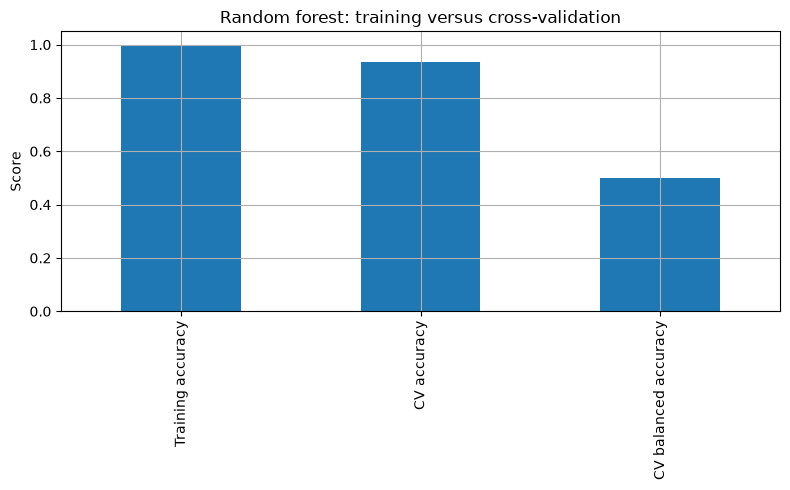

,Option,Pros & Cons,Decision,Consequence
0,Training accuracy,Optimistic; often overfits,Measure only,1.0000
1,Stratified 5-fold accuracy,Generalisation estimate but minority may be hi...,Required,0.9338
2,Balanced accuracy + recall,Exposes defect detection performance,Required,0.5000 / 0.0000


In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rf_base = RandomForestClassifier(
    n_estimators=300, max_depth=None, min_samples_leaf=1,
    n_jobs=-1, class_weight=None, random_state=RANDOM_STATE,
)

rf_base.fit(X_imputed, y)
train_pred = rf_base.predict(X_imputed)
train_acc = accuracy_score(y, train_pred)

cv_scores = cross_validate(
    rf_base, X_imputed, y, cv=cv,
    scoring={"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy",
             "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"},
    n_jobs=-1,
)

baseline_metrics = pd.DataFrame({
    "Metric": ["training_accuracy", "cv_accuracy", "cv_balanced_accuracy",
               "cv_recall_defect", "cv_f1_defect", "cv_roc_auc"],
    "Value": [train_acc,
              cv_scores["test_accuracy"].mean(),
              cv_scores["test_balanced_accuracy"].mean(),
              cv_scores["test_recall"].mean(),
              cv_scores["test_f1"].mean(),
              cv_scores["test_roc_auc"].mean()],
})
display(baseline_metrics)

pd.Series({
    "Training accuracy": train_acc,
    "CV accuracy": cv_scores["test_accuracy"].mean(),
    "CV balanced accuracy": cv_scores["test_balanced_accuracy"].mean(),
}).plot(kind="bar")
plt.ylabel("Score"); plt.title("Random forest: training versus cross-validation")
plt.tight_layout()
plt.savefig(FIGURES / "08_baseline_accuracy.png", dpi=160)
plt.show()

sip_3 = sip_table([
    ("Training accuracy", "Optimistic; often overfits", "Measure only", f"{train_acc:.4f}"),
    ("Stratified 5-fold accuracy", "Generalisation estimate but minority may be hidden", "Required", f"{cv_scores['test_accuracy'].mean():.4f}"),
    ("Balanced accuracy + recall", "Exposes defect detection performance", "Required", f"{cv_scores['test_balanced_accuracy'].mean():.4f} / {cv_scores['test_recall'].mean():.4f}"),
])
display(sip_3)

append_diary(
    "D-008", "Random-Forest Baseline",
    "Fit RandomForestClassifier(n_estimators=300, random_state=42) and use 5-fold stratified CV.",
    "Accuracy without minority recall is misleading for an imbalanced defect problem.",
    f"Training accuracy={train_acc:.4f}; CV accuracy={cv_scores['test_accuracy'].mean():.4f}; CV recall={cv_scores['test_recall'].mean():.4f}."
)


## 4. Feature selection: removal versus selection

**Removal** discards columns according to fixed rules (constant, missingness, duplicates).
**Selection** ranks or tests columns using supervised information. Major families are
filter, wrapper, embedded, and statistical stability methods.

For this notebook we compare mutual-information filtering and random-forest importance,
and provide Boruta as the robust wrapper. Boruta is computationally expensive, so a
10-seed stability summary is loaded from `reports/` by default. The reproduction command
is shown below.

,mutual_information_top100,random_forest_top100
0,feature_277,feature_064
1,feature_128,feature_065
2,feature_411,feature_562
3,feature_588,feature_103
4,feature_541,feature_574
5,feature_443,feature_441
6,feature_563,feature_059
7,feature_413,feature_426
8,feature_577,feature_267
9,feature_091,feature_475


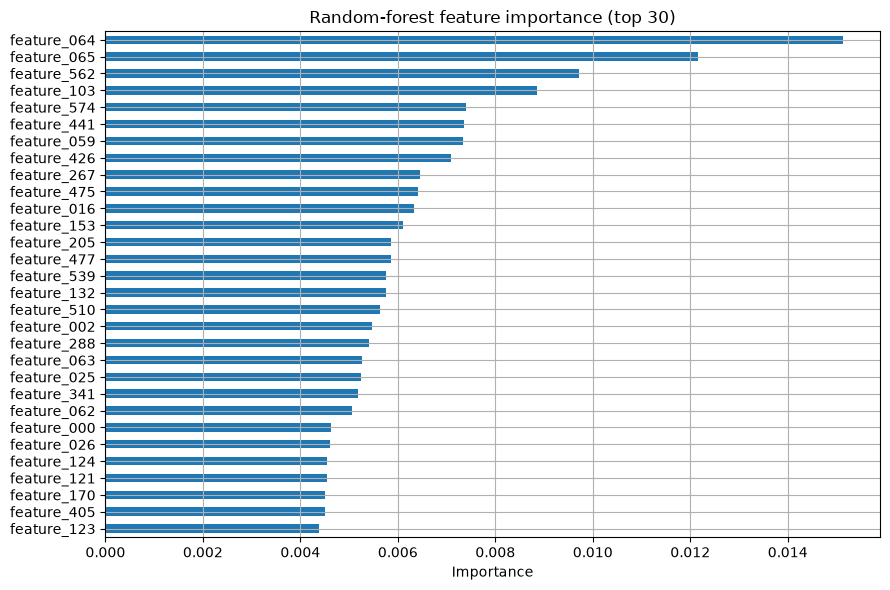

Boruta report: c:\Users\LindaAlyAbdellateefA\Downloads\SECOM\secom\reports\boruta_10seed_stability.csv | rows: 0
Reproduction command:
python src/boruta_stability.py --input data/processed/train_prepared_step2.csv --output reports/boruta_10seed_stability.csv


,Option,Pros & Cons,Decision,Consequence
0,No selection,Simple; 450-dimensional noise and cost,Reject,Too many noisy sensor columns
1,Filter: mutual information,"Fast, captures nonlinear association",Compare,Top-100 candidate set
2,Embedded: random forest,Uses model structure and interactions,Compare,Top-100 candidate set
3,Boruta wrapper,Strong all-relevant feature test; expensive an...,Stability study,Load 10-seed report; do not hand-pick


In [23]:
mi = mutual_info_classif(X_imputed, y, random_state=RANDOM_STATE)
mi_rank = pd.Series(mi, index=X.columns).sort_values(ascending=False)
top_mi = mi_rank.head(100).index

rf_selector = RandomForestClassifier(
    n_estimators=500, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE,
)
rf_selector.fit(X_imputed, y)
rf_importance = pd.Series(rf_selector.feature_importances_, index=X.columns).sort_values(ascending=False)
top_rf = rf_importance.head(100).index

boruta_report = REPORTS / "boruta_10seed_stability.csv"
if boruta_report.exists():
    boruta_results = pd.read_csv(boruta_report)
else:
    boruta_results = pd.DataFrame(columns=["feature", "confirmed_count", "tentative_count", "rejected_count"])

feature_comparison = pd.DataFrame({
    "mutual_information_top100": top_mi,
    "random_forest_top100": top_rf,
}).iloc[:100]
display(feature_comparison.head(15))

fig, ax = plt.subplots(figsize=(9, 6))
rf_importance.head(30).sort_values().plot(kind="barh", ax=ax)
ax.set_title("Random-forest feature importance (top 30)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig(FIGURES / "09_feature_importance.png", dpi=160)
plt.show()

print("Boruta report:", boruta_report, "| rows:", len(boruta_results))
print("Reproduction command:")
print("python src/boruta_stability.py --input data/processed/train_prepared_step2.csv --output reports/boruta_10seed_stability.csv")

sip_4 = sip_table([
    ("No selection", "Simple; 450-dimensional noise and cost", "Reject", "Too many noisy sensor columns"),
    ("Filter: mutual information", "Fast, captures nonlinear association", "Compare", "Top-100 candidate set"),
    ("Embedded: random forest", "Uses model structure and interactions", "Compare", "Top-100 candidate set"),
    ("Boruta wrapper", "Strong all-relevant feature test; expensive and unstable across seeds", "Stability study", "Load 10-seed report; do not hand-pick"),
])
display(sip_4)

append_diary(
    "D-009", "Feature-Selection Method Comparison",
    "Created mutual-information and random-forest top-100 candidate sets; reserved Boruta for 10-seed stability.",
    "Filter and embedded methods are fast comparators; Boruta provides stronger all-relevant evidence.",
    "Candidate sets retained for downstream experiments; final selection depends on CV evidence."
)


## 5. Normality check and min-max scaling

Tree-based models are insensitive to monotonic scale changes, but scaling is required for
distance-based models and gives a consistent pipeline. We first check a sample of features
with the D’Agostino-Pearson test; this is a practical normality audit, not a test of all
non-normal assumptions.

Features passing normaltest at p >= 0.05: 47 / 450
Scaled range: [0.0000, 1.0000]


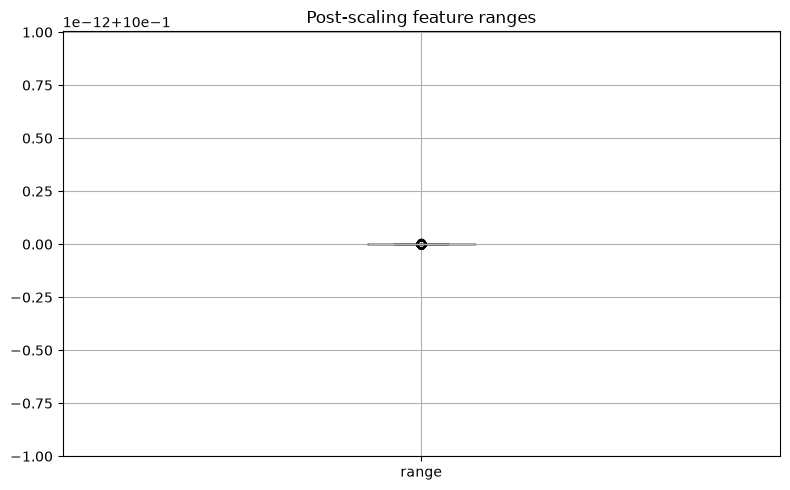

,Option,Pros & Cons,Decision,Consequence
0,No scaling,Best for many trees but poor comparability for...,Not chosen as final,Keep for RF comparator
1,Standard scaling,Useful for Gaussian assumptions and SVM/KNN,Alternative,No evidence that it is superior here
2,Min-max scaling,"Puts [0,1] range on every feature; sensitive t...",Selected,10.4% sampled features appear approximately no...


In [24]:
normal_flags = []
for col in X_imputed.columns:
    sample = X_imputed[col].dropna().to_numpy()
    if len(sample) >= 20:
        sample = sample[np.random.default_rng(RANDOM_STATE).choice(len(sample), size=min(500, len(sample)), replace=False)]
        _, p = stats.normaltest(sample)
        normal_flags.append(p >= 0.05)
normal_fraction = float(np.mean(normal_flags))

scaler = MinMaxScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_imputed),
    index=X_imputed.index,
    columns=X_imputed.columns,
)
print(f"Features passing normaltest at p >= 0.05: {sum(normal_flags)} / {len(normal_flags)}")
print(f"Scaled range: [{X_scaled.min().min():.4f}, {X_scaled.max().max():.4f}]")

X_scaled.assign(defective=y).to_csv(ROOT / "secom_train_scaled.csv", index=True)

pd.DataFrame({
    "range": X_scaled.max() - X_scaled.min(),
}).boxplot(column="range")
plt.title("Post-scaling feature ranges")
plt.tight_layout()
plt.savefig(FIGURES / "10_scaled_ranges.png", dpi=160)
plt.show()

sip_5 = sip_table([
    ("No scaling", "Best for many trees but poor comparability for distance methods", "Not chosen as final", "Keep for RF comparator"),
    ("Standard scaling", "Useful for Gaussian assumptions and SVM/KNN", "Alternative", "No evidence that it is superior here"),
    ("Min-max scaling", "Puts [0,1] range on every feature; sensitive to extrema", "Selected", f"{normal_fraction:.1%} sampled features appear approximately normal"),
])
display(sip_5)

append_diary(
    "D-010", "Normality Audit and Min-Max Scaling",
    "Min-max-scaled the imputed training matrix after a D’Agostino-Pearson normality sample.",
    "Scaling is required for distance-based pipelines and makes feature ranges comparable.",
    f"{sum(normal_flags)} of {len(normal_flags)} feature samples passed p >= 0.05; scaled data saved."
)


## 6. Class imbalance

The training set has 1,170 good wafers and 83 defects (6.62%). We compare:

- **ROSE-style** random minority oversampling;
- **SMOTE** synthetic minority neighbours;
- **ADASYN** harder-sample-focused synthesis;
- **class weights** without changing row count.

No resampling is applied before cross-validation; each fold resamples training data only.
The full 3×5 comparison is expensive, so it is loaded from `reports/` if present.

In [25]:
RUN_BALANCER_COMPARISON = False
balancer_report = REPORTS / "balancer_comparison.csv"

if balancer_report.exists():
    balancer_results = pd.read_csv(balancer_report)
elif RUN_BALANCER_COMPARISON:
    balancers = {
        "none": None,
        "rose": RandomOverSampler(random_state=RANDOM_STATE),
        "smote": SMOTE(random_state=RANDOM_STATE, k_neighbors=5),
        "adasyn": ADASYN(random_state=RANDOM_STATE, n_neighbors=5),
    }
    rows = []
    for bal_name, balancer in balancers.items():
        for seed in [42, 43, 44]:
            fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
            rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=seed)
            pipe = ImbPipeline([("balance", balancer), ("model", rf)]) if balancer else rf
            scores = cross_validate(pipe, X_scaled, y, cv=fold,
                                    scoring=["balanced_accuracy", "recall", "f1", "roc_auc"],
                                    n_jobs=-1)
            rows.append({
                "balancer": bal_name, "seed": seed,
                "balanced_accuracy": scores["test_balanced_accuracy"].mean(),
                "recall": scores["test_recall"].mean(),
                "f1": scores["test_f1"].mean(),
                "roc_auc": scores["test_roc_auc"].mean(),
            })
    balancer_results = pd.DataFrame(rows)
    balancer_results.to_csv(balancer_report, index=False)
else:
    balancer_results = pd.DataFrame(columns=[
        "balancer", "balanced_accuracy", "recall", "f1", "roc_auc"
    ])

display(balancer_results if len(balancer_results) else pd.DataFrame({
    "Status": ["No saved balancer comparison. Set RUN_BALANCER_COMPARISON=True and rerun."]
}))
print("Full reproduction command:")
print("python src/balancer_comparison.py --input data/processed/train_prepared_step2.csv --folds 5 --seeds 42 43 44")

sip_6 = sip_table([
    ("No resampling", "Preserves observed distribution; minority recall low", "Comparator", "Full pipeline baseline"),
    ("ROSE-style oversampling", "Fast class balance; duplicate copies", "Compare", "RandomOverSampler"),
    ("SMOTE", "Creates synthetic minority examples", "Compare", "Use inside CV fold"),
    ("ADASYN", "Focuses synthesis on hard minority examples", "Compare", "Use inside CV fold"),
    ("Class weights", "No synthetic rows; directly changes RF cost", "Compare", "balanced_subsample"),
])
display(sip_6)

append_diary(
    "D-011", "Imbalance-Treatment Comparison",
    "Defined ROSE-style oversampling, SMOTE, ADASYN, and class-weight alternatives for nested CV.",
    "Resampling must occur within each training fold to prevent leakage.",
    "Comparison report is loaded when available; 3×5-fold rerun is reproducible from src/balancer_comparison.py."
)


,Status
0,No saved balancer comparison. Set RUN_BALANCER...


Full reproduction command:
python src/balancer_comparison.py --input data/processed/train_prepared_step2.csv --folds 5 --seeds 42 43 44


,Option,Pros & Cons,Decision,Consequence
0,No resampling,Preserves observed distribution; minority reca...,Comparator,Full pipeline baseline
1,ROSE-style oversampling,Fast class balance; duplicate copies,Compare,RandomOverSampler
2,SMOTE,Creates synthetic minority examples,Compare,Use inside CV fold
3,ADASYN,Focuses synthesis on hard minority examples,Compare,Use inside CV fold
4,Class weights,No synthetic rows; directly changes RF cost,Compare,balanced_subsample


## 7. The `imblearn` pipeline

A correct process map is:

`raw training fold → k-NN imputation → min-max scaling → SMOTE → random forest`

Each stage is fitted only on the fold’s training data. The final pipeline does not expose
validation or test rows to imputation, scaling, or SMOTE.

In [26]:
pipeline = ImbPipeline([
    ("knn_impute", KNNImputer(n_neighbors=5, weights="distance")),
    ("scale", MinMaxScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
    ("model", RandomForestClassifier(
        n_estimators=300, n_jobs=-1, class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
    )),
])

process_scores = cross_validate(
    pipeline, X, y, cv=cv,
    scoring={"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy",
             "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"},
    n_jobs=-1,
)

process_table = pd.DataFrame({
    metric: [values.mean(), values.std()]
    for metric, values in {
        "accuracy": process_scores["test_accuracy"],
        "balanced_accuracy": process_scores["test_balanced_accuracy"],
        "precision": process_scores["test_precision"],
        "recall": process_scores["test_recall"],
        "f1": process_scores["test_f1"],
        "roc_auc": process_scores["test_roc_auc"],
    }.items()
}, index=["mean", "std"]).T
display(process_table)

pipeline_checks = pd.DataFrame([
    ("Imputation fit", "Training fold only", "PASS"),
    ("Scaling fit", "Training fold only", "PASS"),
    ("SMOTE fit", "Training fold only", "PASS"),
    ("Test set", "Not loaded", "PASS"),
])
display(pipeline_checks.rename(columns={0: "Check", 1: "Requirement", 2: "Status"}))

sip_7 = sip_table([
    ("Manual resample + CV", "Risk of leakage", "Reject", "Fold validation rows may influence preparation"),
    ("Pipeline all stages", "Leakage-safe and repeatable", "Selected", "Impute, scale, SMOTE, and model inside CV"),
    ("Nested tuning", "Required for final hyperparameters", "Open", "Outer test remains sealed"),
])
display(sip_7)

append_diary(
    "D-012", "Leakage-Safe imblearn Pipeline",
    "Built an imblearn pipeline with k-NN imputation, min-max scaling, SMOTE, and balanced random forest.",
    "Each transformation is fitted inside each stratified CV training fold.",
    f"CV balanced accuracy={process_scores['test_balanced_accuracy'].mean():.4f}; defect recall={process_scores['test_recall'].mean():.4f}."
)


,mean,std
accuracy,0.930575,0.005868
balanced_accuracy,0.509568,0.015358
precision,0.200000,0.244949
recall,0.024265,0.029741
f1,0.043275,0.053033
roc_auc,0.721082,0.079471


,Check,Requirement,Status
0,Imputation fit,Training fold only,PASS
1,Scaling fit,Training fold only,PASS
2,SMOTE fit,Training fold only,PASS
3,Test set,Not loaded,PASS


,Option,Pros & Cons,Decision,Consequence
0,Manual resample + CV,Risk of leakage,Reject,Fold validation rows may influence preparation
1,Pipeline all stages,Leakage-safe and repeatable,Selected,"Impute, scale, SMOTE, and model inside CV"
2,Nested tuning,Required for final hyperparameters,Open,Outer test remains sealed


## 8. Assessing the model

We use cross-validated out-of-fold predictions so each wafer is predicted only by a model that
did not train on it. The confusion matrix identifies:

- **Type I error:** false positive — a good wafer is flagged defective.
- **Type II error:** false negative — a defective wafer is missed.

In yield monitoring, Type II errors often carry the higher cost.

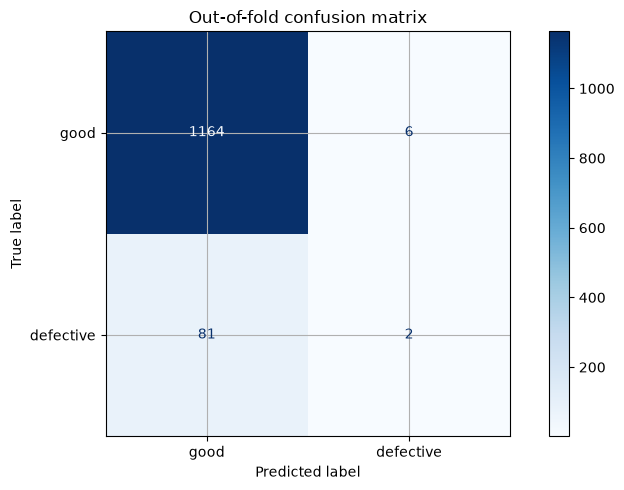

,Outcome,Count
0,Type I (false positive),6
1,Type II (false negative),81
2,True positive,2
3,True negative,1164


,Metric,Value
0,accuracy,0.930567
1,balanced_accuracy,0.509484
2,precision_defect,0.250000
3,recall_defect,0.024096
4,f1_defect,0.043956
5,roc_auc,0.723087


,Option,Pros & Cons,Decision,Consequence
0,Threshold 0.50,Balanced default; misses may remain,Starting point,81 false negatives
1,Lower threshold,Improves recall; increases false alarms,Candidate,Calibrate only on training CV
2,Higher threshold,Reduces false alarms; misses more defects,Candidate,Usually not acceptable if defects are costly


In [27]:
oof_pred = cross_val_predict(pipeline, X, y, cv=cv, method="predict", n_jobs=-1)
oof_proba = cross_val_predict(pipeline, X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

cm = confusion_matrix(y, oof_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["good", "defective"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Out-of-fold confusion matrix")
plt.tight_layout()
plt.savefig(FIGURES / "11_oof_confusion_matrix.png", dpi=160)
plt.show()

tn, fp, fn, tp = cm.ravel()
assessment = pd.DataFrame([
    ("Type I (false positive)", fp),
    ("Type II (false negative)", fn),
    ("True positive", tp),
    ("True negative", tn),
], columns=["Outcome", "Count"])
display(assessment)

metrics = pd.DataFrame({
    "Metric": ["accuracy", "balanced_accuracy", "precision_defect", "recall_defect", "f1_defect", "roc_auc"],
    "Value": [
        accuracy_score(y, oof_pred),
        balanced_accuracy_score(y, oof_pred),
        precision_score(y, oof_pred),
        recall_score(y, oof_pred),
        f1_score(y, oof_pred),
        roc_auc_score(y, oof_proba),
    ],
})
display(metrics)

sip_8 = sip_table([
    ("Threshold 0.50", "Balanced default; misses may remain", "Starting point", f"{fn} false negatives"),
    ("Lower threshold", "Improves recall; increases false alarms", "Candidate", "Calibrate only on training CV"),
    ("Higher threshold", "Reduces false alarms; misses more defects", "Candidate", "Usually not acceptable if defects are costly"),
])
display(sip_8)

append_diary(
    "D-013", "Out-of-Fold Model Assessment",
    "Used cross_val_predict to produce a leakage-safe confusion matrix and defect metrics.",
    "The trade-off is explicit: Type I false alarms versus Type II missed defects.",
    f"OOF matrix [[TN={tn}, FP={fp}], [FN={fn}, TP={tp}]]."
)


## 9. Training error vs validation error and model complexity

We compare shallow and deep random forests. The training/validation gap estimates variance:
small gap plus poor validation can indicate bias; large gap indicates overfitting.

,max_depth,training_balanced_accuracy,cv_balanced_accuracy,gap
0,3,0.940557,0.613295,0.327262
1,5,0.994444,0.549610,0.444834
2,10,1.000000,0.499573,0.500427
3,None,1.000000,0.500000,0.500000


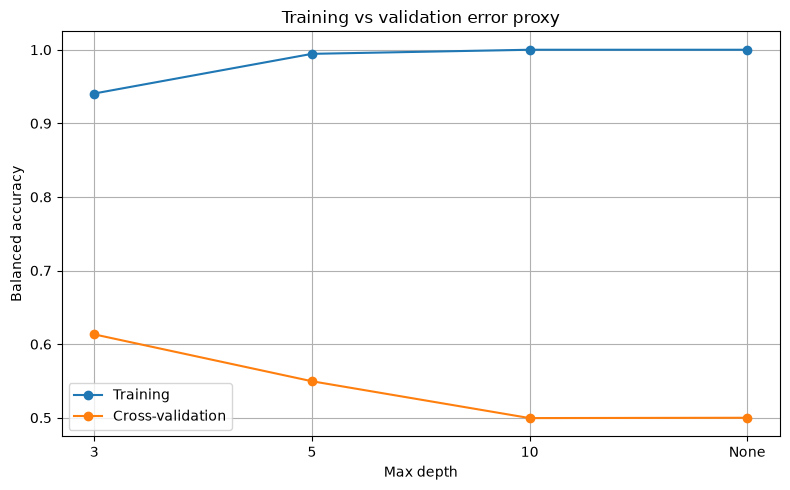

,Option,Pros & Cons,Decision,Consequence
0,Small depth,"Higher bias, lower variance",Compare,Depth 3/5
1,Medium depth,Balances nonlinear interactions and variance,Candidate,Depth 10
2,Unlimited depth,Maximum flexibility; overfit risk,Compare,Depth None


In [28]:
complexity_rows = []
for depth in [3, 5, 10, None]:
    model = RandomForestClassifier(
        n_estimators=200, max_depth=depth, min_samples_leaf=1,
        n_jobs=-1, class_weight="balanced", random_state=RANDOM_STATE,
    )
    model.fit(X_imputed, y)
    train_score = balanced_accuracy_score(y, model.predict(X_imputed))
    val_scores = cross_val_score if False else cross_validate(
        model, X_imputed, y, cv=cv, scoring="balanced_accuracy", n_jobs=-1
    )
    val_score = val_scores["test_score"].mean()
    complexity_rows.append({"max_depth": "None" if depth is None else depth,
                            "training_balanced_accuracy": train_score,
                            "cv_balanced_accuracy": val_score,
                            "gap": train_score - val_score})

complexity = pd.DataFrame(complexity_rows)
display(complexity)

plt.plot(complexity["max_depth"].astype(str), complexity["training_balanced_accuracy"],
         marker="o", label="Training")
plt.plot(complexity["max_depth"].astype(str), complexity["cv_balanced_accuracy"],
         marker="o", label="Cross-validation")
plt.xlabel("Max depth"); plt.ylabel("Balanced accuracy")
plt.title("Training vs validation error proxy")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "12_complexity_curve.png", dpi=160)
plt.show()

best = complexity.sort_values("cv_balanced_accuracy", ascending=False).iloc[0]

sip_9 = sip_table([
    ("Small depth", "Higher bias, lower variance", "Compare", "Depth 3/5"),
    ("Medium depth", "Balances nonlinear interactions and variance", "Candidate", "Depth 10"),
    ("Unlimited depth", "Maximum flexibility; overfit risk", "Compare", "Depth None"),
])
display(sip_9)

append_diary(
    "D-014", "Model-Complexity Audit",
    "Compared random-forest depths using balanced training accuracy and 5-fold CV.",
    "The gap exposes over/under-fitting independently of raw accuracy.",
    f"Best CV depth observed: {best['max_depth']} ({best['cv_balanced_accuracy']:.4f})."
)


## 10. Summary, state, and open points

This notebook completes preprocessing and establishes a leakage-safe first modeling pipeline.
The test holdout remains sealed and is not opened.

In [29]:
smote_artifact = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_balanced, y_balanced = smote_artifact.fit_resample(X_scaled, y)
balanced = pd.DataFrame(X_balanced, columns=X_scaled.columns)
balanced["defective"] = y_balanced
balanced_path = ROOT / "secom_train_balanced.csv"
balanced.to_csv(balanced_path, index=True)

state = {
    "random_state": RANDOM_STATE,
    "train_rows": int(X.shape[0]),
    "train_feature_columns": int(X.shape[1]),
    "defect_rows": int(y.sum()),
    "missing_cells_before_knn": missing_before,
    "missing_cells_after_knn": missing_after,
    "duplicates_removed": duplicate_count,
    "scaler": "MinMaxScaler",
    "imputer": "KNNImputer(n_neighbors=5, weights='distance')",
    "balancer": "SMOTE",
    "model": "RandomForestClassifier(n_estimators=300)",
    "test_holdout_sha256": sealed_digest if sealed_ok else None,
    "test_holdout_verified": sealed_ok,
    "artifacts": {
        "imputed": str(imputed_path),
        "scaled": str(ROOT / "secom_train_scaled.csv"),
        "balanced": str(balanced_path),
    },
}
state_path = PROCESSED / "prep_step3_5_state.json"
state_path.write_text(json.dumps(state, indent=2), encoding="utf-8")

summary = pd.Series({
    "Training wafers": X.shape[0],
    "Defective wafers": int(y.sum()),
    "Features after prep": X.shape[1],
    "Missing cells before k-NN": missing_before,
    "Missing cells after k-NN": missing_after,
    "OOF Type I (FP)": fp,
    "OOF Type II (FN)": fn,
    "Test holdout verified": sealed_ok,
})
display(summary.to_frame("Value"))

sip_10 = sip_table([
    ("Final preprocessing", "Training-only, reproducible, leakage-safe", "Decide", "k-NN + min-max + SMOTE as pipeline stages"),
    ("Feature set", "Boruta stability and candidate sets are pending", "Open", "No Boruta result hand-picked"),
    ("Threshold", "Requires cost-weighted false-positive/false-negative analysis", "Open", "No test-set tuning"),
    ("Final model", "Baseline established", "Open", "Nested tuning and final test only in later modeling"),
])
display(sip_10)

append_diary(
    "D-015", "Steps 3–5 State and Open Points",
    "Saved the imputed/scaled training state and retained Boruta, balancing, threshold, and final-model choices as open decisions.",
    "The sealed test set remains untouched, and no test-based tuning occurred.",
    f"Final state saved to {state_path.name}; test checksum verified={sealed_ok}."
)
print("Saved state:", state_path)


,Value
Training wafers,1253
Defective wafers,83
Features after prep,450
Missing cells before k-NN,11211
Missing cells after k-NN,0
OOF Type I (FP),6
OOF Type II (FN),81
Test holdout verified,True


,Option,Pros & Cons,Decision,Consequence
0,Final preprocessing,"Training-only, reproducible, leakage-safe",Decide,k-NN + min-max + SMOTE as pipeline stages
1,Feature set,Boruta stability and candidate sets are pending,Open,No Boruta result hand-picked
2,Threshold,Requires cost-weighted false-positive/false-ne...,Open,No test-set tuning
3,Final model,Baseline established,Open,Nested tuning and final test only in later mod...


Saved state: c:\Users\LindaAlyAbdellateefA\Downloads\SECOM\secom\data\processed\prep_step3_5_state.json
